# 数据地址

https://www.10xgenomics.com/jp/datasets/xenium-human-lung-preview-data-1-standard?utm_source=chatgpt.com \
第一优先级 \
transcripts.parquet \
transcripts.csv.gz \
transcripts.zarr.zip \
cells.parquet \
cells.csv.gz \
cells.zarr.zip \
cell_feature_matrix.h5 \
cell_feature_matrix.tar.gz \
cell_feature_matrix.zarr.zip

第二优先级 \
cell_boundaries.parquet \
cell_boundaries.csv.gz \
nucleus_boundaries.parquet \
nucleus_boundaries.csv.gz \
morphology.ome.tif \
morphology_focus.ome.tif \
morphology_mip.ome.tif

第三优先级 \
gene_panel.json \
experiment.xenium \
metrics_summary.csv

第四优先级 \
analysis.tar.gz \
analysis.zarr.zip \
analysis_summary.html

In [1]:
from pathlib import Path

PATH_Xenium = Path(r"E:\Data\Xenium_Preview_Human_Non_diseased_Lung_With_Add_on_FFPE_outs")

#  拆解数据 - transcripts.parquet
记录每一条转录本对应的基因、所属细胞、空间坐标、核相关位置及检测质量等信息

transcript_id：每条转录本的唯一编号 \
cell_id：该转录本被分配到的细胞编号 \
overlaps_nucleus：该转录本是否位于细胞核区域内，1表示是，0表示否 \
feature_name：该转录本对应的基因或检测特征名称 \
x_location：该转录本在组织中的 X 轴空间坐标 \
y_location：该转录本在组织中的 Y 轴空间坐标 \
z_location：该转录本在组织中的 Z 轴空间坐标 \
qv：该转录本检测结果的质量值，数值越高通常表示可信度越高 \
fov_name：该转录本所在的成像视野编号，即 Field of View \
nucleus_distance：该转录本到细胞核区域的距离

In [8]:
import pyarrow.parquet as pq

file_path = PATH_Xenium / "transcripts.parquet"

# 打开 parquet，不读取全部数据
pf = pq.ParquetFile(file_path)

# 1. 看整体形状
rows = pf.metadata.num_rows
cols = pf.metadata.num_columns

print("shape:", (rows, cols))

# 2. 看列名
print("\ncolumns:")
print(pf.schema.names)

# 3. 只读取前一个 row group
table = pf.read_row_group(0)

df = table.to_pandas()

print("\n前一个 row group 的 shape:")
print(df.shape)

print("\n前5行:")
print(df.head())

print("\n数据类型:")
print(df.dtypes)

shape: (1000000, 10)

columns:
['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv', 'fov_name', 'nucleus_distance']

前一个 row group 的 shape:
(1000000, 10)

前5行:
     transcript_id        cell_id  overlaps_nucleus feature_name   x_location  \
0  281474976710658  b'jhkhchoa-1'                 0     b'SEC62'  4816.278320   
1  281474976710668  b'jiggkode-1'                 0    b'IL1RL1'  4819.871094   
2  281474976710671  b'jiggncfh-1'                 0    b'COMMD6'  4820.274902   
3  281474976710677  b'jhokcdbh-1'                 1    b'IL1RL1'  4825.383301   
4  281474976710678  b'jigipkbj-1'                 0    b'RUVBL2'  4825.897461   

    y_location  z_location         qv fov_name  nucleus_distance  
0  6496.021973   16.099773  40.000000  b'AA10'          0.000000  
1  6248.158691   17.321672   7.707156  b'AA10'          0.000000  
2  6201.342285   16.184324  31.194069  b'AA10'          8.180201  
3  6431.100586   16.99005

#  拆解数据 - transcripts.csv.gz

transcripts.csv.gz 记录每一条转录本对应的基因、所属细胞、空间坐标、细胞核相关位置及检测质量等信息 \

transcript_id：每条转录本的唯一编号 \
cell_id：该转录本被分配到的细胞编号 \
overlaps_nucleus：该转录本是否位于细胞核区域内，1表示是，0表示否 \
feature_name：该转录本对应的基因或检测特征名称 \
x_location：该转录本在组织中的 X 轴空间坐标 \
y_location：该转录本在组织中的 Y 轴空间坐标 \
z_location：该转录本在组织中的 Z 轴空间坐标 \
qv：该转录本检测结果的质量值 \
fov_name：该转录本所在的成像视野编号 \
nucleus_distance：该转录本到细胞核区域的距离 \
transcripts.csv.gz 与 transcripts.parquet 字段结构相同，但包含约 2859 万条转录本记录，数据量更完整

In [9]:
import pandas as pd
import gzip

file_path = PATH_Xenium / "transcripts.csv.gz"

# 1. shape
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

df = pd.read_csv(file_path, nrows=5)

print("shape:")
print((total_rows, len(df.columns)))

# 2. columns
print("\ncolumns:")
print(df.columns.tolist())

# 3. 前一个数据块的 shape
chunk = pd.read_csv(file_path, nrows=100000)

print("\n前一个数据块的 shape:")
print(chunk.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(28598591, 10)

columns:
['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv', 'fov_name', 'nucleus_distance']

前一个数据块的 shape:
(100000, 10)

前5行:
     transcript_id     cell_id  overlaps_nucleus feature_name  x_location  \
0  281474976710658  jhkhchoa-1                 0        SEC62   4816.2783   
1  281474976710668  jiggkode-1                 0       IL1RL1   4819.8710   
2  281474976710671  jiggncfh-1                 0       COMMD6   4820.2750   
3  281474976710677  jhokcdbh-1                 1       IL1RL1   4825.3833   
4  281474976710678  jigipkbj-1                 0       RUVBL2   4825.8975   

   y_location  z_location         qv fov_name  nucleus_distance  
0   6496.0220   16.099773  40.000000     AA10          0.000000  
1   6248.1587   17.321672   7.707156     AA10          0.000000  
2   6201.3423   16.184324  31.194069     AA10          8.180201  
3   6431.1006   16.990051  25.460758     AA10          0.0000

# 数据拆解 - transcripts.zarr.zip

`transcripts.zarr.zip`：以分层的 Zarr 结构存储转录本空间信息，整体主要分为 `density` 和 `grids` 两部分。

`density` 是转录本汇总后的空间密度数据，其中 `gene` 表示基因层面的空间密度信息；`data` 保存稀疏矩阵中的非零数值，`indices` 保存这些数值对应的位置索引，`indptr` 用于标记稀疏矩阵各部分的起始位置。

`grids` 是具体的空间网格数据，即把整个组织空间划分成多个网格，每个网格中保存落在该区域内的转录本信息。

每个 `grid` 下包含 `id`、`uuid`、`valid`、`status`、`location`、`gene_identity` 和 `quality_score` 等字段，其中 `id` 表示转录本内部编号，`uuid` 表示唯一标识，`valid` 表示记录是否有效，`status` 表示状态编码，`location` 表示三维空间坐标，`gene_identity` 表示对应基因的内部编号，`quality_score` 表示检测质量分数。

In [15]:
import zarr
from zarr.storage import ZipStore

file_path = PATH_Xenium / "transcripts.zarr.zip"

store = ZipStore(str(file_path), mode="r")
root = zarr.open_group(store=store, mode="r")

# =========================
# 1. 顶层结构
# =========================
print("===== transcripts.zarr.zip 顶层 =====")

for key in root.keys():
    obj = root[key]

    if isinstance(obj, zarr.Group):
        print(f"{key} -> Group")

    elif isinstance(obj, zarr.Array):
        print(
            f"{key} -> Array | "
            f"shape={obj.shape} | dtype={obj.dtype}"
        )

# =========================
# 2. density
# =========================
print("\n===== density =====")

density = root["density"]

for key in density.keys():
    obj = density[key]

    print(f"\n{key} -> {type(obj).__name__}")

    if isinstance(obj, zarr.Group):

        for subkey in obj.keys():
            arr = obj[subkey]

            if isinstance(arr, zarr.Array):
                print(
                    f"  {subkey} | "
                    f"shape={arr.shape} | "
                    f"dtype={arr.dtype}"
                )

                print("  前10个值:")
                print(arr[:10])

# =========================
# 3. grids 第一层
# =========================
print("\n===== grids =====")

grids = root["grids"]

print("grids 第一层 keys:")
print(list(grids.keys()))


# =========================
# 4. 找第一个实际 grid
# =========================
def find_first_grid(group, path=""):
    for key in group.keys():

        obj = group[key]

        new_path = f"{path}/{key}" if path else key

        if isinstance(obj, zarr.Group):

            # 如果这个 group 下面已经直接有 array
            array_keys = list(obj.array_keys())

            if len(array_keys) > 0:
                return new_path, obj

            result = find_first_grid(obj, new_path)

            if result is not None:
                return result

    return None


result = find_first_grid(grids, "grids")

# =========================
# 5. 查看一个具体 grid
# =========================
if result is not None:

    grid_path, grid = result

    print("\n===== 示例 grid =====")
    print("路径:")
    print(grid_path)

    print("\n字段:")
    print(list(grid.array_keys()))

    for key in grid.array_keys():
        arr = grid[key]

        print(f"\n--- {key} ---")
        print("shape:", arr.shape)
        print("dtype:", arr.dtype)

        print("前5个值:")
        print(arr[:5])

store.close()

===== transcripts.zarr.zip 顶层 =====
density -> Group
grids -> Group

===== density =====

gene -> Group
  data | shape=(17066310,) | dtype=uint16
  前10个值:
[1 1 1 1 1 1 1 1 1 1]
  indices | shape=(17066310,) | dtype=uint16
  前10个值:
[ 523 1000  636  698  410  441  432  329  330  419]
  indptr | shape=(548034,) | dtype=uint32
  前10个值:
[0 0 0 0 0 0 0 0 0 0]

===== grids =====
grids 第一层 keys:
['0', '1', '2', '3', '4', '5', '6']

===== 示例 grid =====
路径:
grids/0/0,2

字段:
['id', 'uuid', 'valid', 'status', 'location', 'gene_identity', 'quality_score']

--- id ---
shape: (3, 2)
dtype: uint32
前5个值:
[[14943   116]
 [18649   116]
 [22702   116]]

--- uuid ---
shape: (3, 2)
dtype: uint32
前5个值:
[[14943 65652]
 [18649 65652]
 [22702 65652]]

--- valid ---
shape: (3, 1)
dtype: uint8
前5个值:
[[1]
 [1]
 [1]]

--- status ---
shape: (3, 1)
dtype: uint8
前5个值:
[[0]
 [0]
 [0]]

--- location ---
shape: (3, 3)
dtype: float32
前5个值:
[[ 63.427643 727.18604   11.612635]
 [133.62485  737.92194   11.731263]
 [ 31.92992

# 数据拆解 - cells.parquet

cells.parquet：记录每个细胞的空间中心位置、转录本数量、各类计数信息以及细胞和细胞核面积 \

cell_id：每个细胞的唯一编号 \
x_centroid：该细胞中心点的 X 轴空间坐标 \
y_centroid：该细胞中心点的 Y 轴空间坐标 \
transcript_counts：该细胞中检测到的目标转录本数量 \
control_probe_counts：该细胞中检测到的控制探针计数 \
control_codeword_counts：该细胞中检测到的控制码字计数 \
unassigned_codeword_counts：该细胞中未能分配到目标基因的码字计数 \
total_counts：该细胞中所有计数的总和 \
cell_area：该细胞的面积 \
nucleus_area：该细胞核的面积

In [17]:
import pyarrow.parquet as pq

file_path = PATH_Xenium / "cells.parquet"

# 打开 parquet
pf = pq.ParquetFile(file_path)

# 1. shape
rows = pf.metadata.num_rows
cols = pf.metadata.num_columns

print("shape:")
print((rows, cols))

# 2. columns
print("\ncolumns:")
print(pf.schema.names)

# 3. 第一个 row group 的 shape
table = pf.read_row_group(0)
df = table.to_pandas()

print("\n第一个 row group 的 shape:")
print(df.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(295883, 10)

columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

第一个 row group 的 shape:
(295883, 10)

前5行:
         cell_id   x_centroid  y_centroid  transcript_counts  \
0  b'aaaaaahk-1'   497.832559  855.178702                 15   
1  b'aaaacfah-1'  1666.102203  833.024384                 19   
2  b'aaaafpoc-1'  1738.557751  862.826160                 64   
3  b'aaaaimpp-1'  1702.586523  836.296915                 80   
4  b'aaaakahi-1'  1755.659229  865.216733                151   

   control_probe_counts  control_codeword_counts  unassigned_codeword_counts  \
0                     0                        0                           0   
1                     0                        0                           0   
2                     0                        0                           0   
3                     0            

# 数据拆解 - cells.csv.gz
同上

In [18]:
import pandas as pd
import gzip

file_path = PATH_Xenium / "cells.csv.gz"

# 1. shape
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

df = pd.read_csv(file_path, nrows=5)

print("shape:")
print((total_rows, len(df.columns)))

# 2. columns
print("\ncolumns:")
print(df.columns.tolist())

# 3. 前一个数据块的 shape
chunk = pd.read_csv(file_path, nrows=100000)

print("\n前一个数据块的 shape:")
print(chunk.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(295883, 10)

columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

前一个数据块的 shape:
(100000, 10)

前5行:
      cell_id   x_centroid  y_centroid  transcript_counts  \
0  aaaaaahk-1   497.832559  855.178702                 15   
1  aaaacfah-1  1666.102203  833.024384                 19   
2  aaaafpoc-1  1738.557751  862.826160                 64   
3  aaaaimpp-1  1702.586523  836.296915                 80   
4  aaaakahi-1  1755.659229  865.216733                151   

   control_probe_counts  control_codeword_counts  unassigned_codeword_counts  \
0                     0                        0                           0   
1                     0                        0                           0   
2                     0                        0                           0   
3                     0                        0             

# 数据拆解 - cells.zarr.zip
没整明白

In [19]:
import zarr
from zarr.storage import ZipStore

file_path = PATH_Xenium / "cells.zarr.zip"

store = ZipStore(str(file_path), mode="r")
root = zarr.open_group(store=store, mode="r")

# 1. 顶层结构
print("===== cells.zarr.zip 顶层 =====")

for key in root.keys():
    obj = root[key]

    if isinstance(obj, zarr.Group):
        print(f"{key} -> Group")

    elif isinstance(obj, zarr.Array):
        print(
            f"{key} -> Array | "
            f"shape={obj.shape} | dtype={obj.dtype}"
        )

# 2. 递归查看结构，但只打印层级、shape、dtype
print("\n===== 完整层级结构 =====")


def show_structure(group, prefix=""):
    for key in group.keys():

        obj = group[key]
        path = f"{prefix}/{key}" if prefix else key

        if isinstance(obj, zarr.Group):
            print(f"[Group] {path}")
            show_structure(obj, path)

        elif isinstance(obj, zarr.Array):
            print(
                f"[Array] {path} | "
                f"shape={obj.shape} | "
                f"dtype={obj.dtype}"
            )


show_structure(root)


# 3. 找第一个真正存数据的 group
def find_first_leaf_group(group, path=""):
    for key in group.keys():

        obj = group[key]
        new_path = f"{path}/{key}" if path else key

        if isinstance(obj, zarr.Group):

            array_keys = list(obj.array_keys())

            if len(array_keys) > 0:
                return new_path, obj

            result = find_first_leaf_group(obj, new_path)

            if result is not None:
                return result

    return None


result = find_first_leaf_group(root)

if result is not None:

    group_path, group = result

    print("\n===== 第一个实际数据 group =====")
    print("路径:")
    print(group_path)

    print("\n字段:")
    print(list(group.array_keys()))

    for key in group.array_keys():
        arr = group[key]

        print(f"\n--- {key} ---")
        print("shape:", arr.shape)
        print("dtype:", arr.dtype)

        print("前5个值:")
        print(arr[:5])

store.close()

===== cells.zarr.zip 顶层 =====
polygon_vertices -> Array | shape=(2, 295883, 26) | dtype=float32
seg_mask_value -> Array | shape=(295883,) | dtype=uint32
cell_id -> Array | shape=(295883, 2) | dtype=uint32
polygon_num_vertices -> Array | shape=(2, 295883) | dtype=int32
cell_summary -> Array | shape=(295883, 7) | dtype=float64
masks -> Group

===== 完整层级结构 =====
[Array] polygon_vertices | shape=(2, 295883, 26) | dtype=float32
[Array] seg_mask_value | shape=(295883,) | dtype=uint32
[Array] cell_id | shape=(295883, 2) | dtype=uint32
[Array] polygon_num_vertices | shape=(2, 295883) | dtype=int32
[Array] cell_summary | shape=(295883, 7) | dtype=float64
[Group] masks
[Array] masks/homogeneous_transform | shape=(4, 4) | dtype=float32
[Array] masks/0 | shape=(47696, 51148) | dtype=uint32
[Array] masks/1 | shape=(47696, 51148) | dtype=uint32

===== 第一个实际数据 group =====
路径:
masks

字段:
['homogeneous_transform', '0', '1']

--- homogeneous_transform ---
shape: (4, 4)
dtype: float32
前5个值:
[[4.7058825 0

# 数据拆解 - cell_feature_matrix.h5

cell_feature_matrix.h5：保存细胞 × 基因的表达计数矩阵，以及细胞 ID 和基因注释信息 \
matrix：整个表达矩阵及其相关信息 \
barcodes：295883 个细胞的 ID \
features：541 个检测基因的注释信息 \
features/name：基因名称，例如 ACE、ACE2、ACKR1 \
features/id：基因对应的 Ensembl ID \
features/feature_type：feature 类型，这里主要是 Gene Expression \
features/genome：feature 对应的基因组来源 \
data：稀疏矩阵中所有非零的表达计数 \
indices：记录这些非零表达值对应的是哪个基因 \
indptr：记录每个细胞在 data 和 indices 中对应数据的起止位置 \
shape：完整表达矩阵大小，为 541 × 295883 \
展开后的矩阵结构是： \
行：541 个基因 \
列：295883 个细胞 \
值：某个细胞中某个基因检测到的 transcript count \
例如第一个细胞 aaaaaahk-1 中，ACE=1、IGFBP3=4，表示该细胞中分别检测到 1 条 ACE transcript 和 4 条 IGFBP3 transcript

In [22]:
import h5py
import numpy as np
import pandas as pd
from scipy.sparse import csc_matrix

file_path = PATH_Xenium / "cell_feature_matrix.h5"

with h5py.File(file_path, "r") as f:
    matrix = f["matrix"]

    # =========================
    # 1. 读取基本信息
    # =========================
    shape = matrix["shape"][:]

    gene_names = matrix["features"]["name"][:].astype(str)
    gene_ids = matrix["features"]["id"][:].astype(str)
    cell_ids = matrix["barcodes"][:].astype(str)

    print("===== 矩阵 shape =====")
    print(shape)

    print("\n基因数:")
    print(len(gene_names))

    print("\n细胞数:")
    print(len(cell_ids))

    # =========================
    # 2. 看行和列是谁
    # =========================
    print("\n===== 前10个基因 =====")
    for i in range(10):
        print(i, gene_names[i], gene_ids[i])

    print("\n===== 前10个细胞 =====")
    for i in range(10):
        print(i, cell_ids[i])

    # =========================
    # 3. 还原稀疏矩阵
    # =========================
    data = matrix["data"][:]
    indices = matrix["indices"][:]
    indptr = matrix["indptr"][:]

    expr = csc_matrix(
        (data, indices, indptr),
        shape=tuple(shape)
    )

    print("\n===== 稀疏矩阵 =====")
    print("shape:", expr.shape)
    print("非零元素数:", expr.nnz)

    # =========================
    # 4. 看前10个基因 × 前10个细胞
    # =========================
    small = expr[:10, :10].toarray()

    df_small = pd.DataFrame(
        small,
        index=gene_names[:10],
        columns=cell_ids[:10]
    )

    print("\n===== 前10个基因 × 前10个细胞 =====")
    print(df_small)

    # =========================
    # 5. 看第一个细胞表达了哪些基因
    # =========================
    first_cell = expr[:, 0].toarray().ravel()

    expressed = pd.DataFrame({
        "gene": gene_names,
        "count": first_cell
    })

    expressed = expressed[expressed["count"] > 0]

    print("\n===== 第一个细胞的非零表达基因 =====")
    print(expressed.head(20))

===== 矩阵 shape =====
[   541 295883]

基因数:
541

细胞数:
295883

===== 前10个基因 =====
0 ACE ENSG00000159640
1 ACE2 ENSG00000130234
2 ACKR1 ENSG00000213088
3 ACTR3 ENSG00000115091
4 ADAM17 ENSG00000151694
5 ADAM28 ENSG00000042980
6 ADAMTS1 ENSG00000154734
7 ADGRE5 ENSG00000123146
8 ADGRL4 ENSG00000162618
9 AGER ENSG00000204305

===== 前10个细胞 =====
0 aaaaaahk-1
1 aaaacfah-1
2 aaaafpoc-1
3 aaaaimpp-1
4 aaaakahi-1
5 aaaakjpi-1
6 aaaandcd-1
7 aaaapmak-1
8 aaabddnp-1
9 aaabdhck-1

===== 稀疏矩阵 =====
shape: (541, 295883)
非零元素数: 14547580

===== 前10个基因 × 前10个细胞 =====
         aaaaaahk-1  aaaacfah-1  aaaafpoc-1  aaaaimpp-1  aaaakahi-1  \
ACE               1           0           0           0           0   
ACE2              0           0           0           0           0   
ACKR1             0           0           0           0           0   
ACTR3             0           0           3           1           3   
ADAM17            0           1           0           0           0   
ADAM28            

# 数据拆解 - cell_feature_matrix.tar.gz

cell_feature_matrix.tar.gz：以 Matrix Market 的三文件形式保存细胞 × 基因表达矩阵，内容与 cell_feature_matrix.h5 属于同一类表达数据 \
barcodes.tsv.gz：保存 295883 个细胞的 ID，每一行对应一个细胞，例如 aaaaaahk-1 \
features.tsv.gz：保存 541 个检测基因的信息，每一行包含 Ensembl 基因 ID、基因名称和 feature 类型，例如 ENSG00000159640、ACE、Gene Expression \
matrix.mtx.gz：保存 541 个基因 × 295883 个细胞的稀疏表达计数矩阵，只记录非零表达值，因此不需要把大量 0 全部存下来 \
matrix.mtx.gz 中的 541 295883 14547580 表示矩阵有 541 个基因、295883 个细胞，以及 14547580 个非零表达值 \
matrix.mtx.gz 后面的每一行按照“基因编号、细胞编号、表达计数”的形式记录，例如 176 1 4 表示第 176 个基因在第 1 个细胞中的表达计数为 4

In [24]:
import tarfile
import gzip
import io

file_path = PATH_Xenium / "cell_feature_matrix.tar.gz"

with tarfile.open(file_path, "r:gz") as tar:
    # =========================
    # 1. barcodes.tsv.gz
    # =========================
    member = tar.getmember(
        "cell_feature_matrix/barcodes.tsv.gz"
    )

    raw = tar.extractfile(member).read()

    with gzip.GzipFile(fileobj=io.BytesIO(raw)) as gz:
        text = gz.read().decode("utf-8")

    print("===== barcodes.tsv.gz 前10行 =====")
    print("\n".join(text.splitlines()[:10]))

    # =========================
    # 2. features.tsv.gz
    # =========================
    member = tar.getmember(
        "cell_feature_matrix/features.tsv.gz"
    )

    raw = tar.extractfile(member).read()

    with gzip.GzipFile(fileobj=io.BytesIO(raw)) as gz:
        text = gz.read().decode("utf-8")

    print("\n===== features.tsv.gz 前10行 =====")
    print("\n".join(text.splitlines()[:10]))

    # =========================
    # 3. matrix.mtx.gz
    # =========================
    member = tar.getmember(
        "cell_feature_matrix/matrix.mtx.gz"
    )

    raw = tar.extractfile(member).read()

    with gzip.GzipFile(fileobj=io.BytesIO(raw)) as gz:
        text = gz.read(3000).decode("utf-8")

    print("\n===== matrix.mtx.gz 前20行 =====")
    print("\n".join(text.splitlines()[:20]))

===== barcodes.tsv.gz 前10行 =====
aaaaaahk-1
aaaacfah-1
aaaafpoc-1
aaaaimpp-1
aaaakahi-1
aaaakjpi-1
aaaandcd-1
aaaapmak-1
aaabddnp-1
aaabdhck-1

===== features.tsv.gz 前10行 =====
ENSG00000159640	ACE	Gene Expression
ENSG00000130234	ACE2	Gene Expression
ENSG00000213088	ACKR1	Gene Expression
ENSG00000115091	ACTR3	Gene Expression
ENSG00000151694	ADAM17	Gene Expression
ENSG00000042980	ADAM28	Gene Expression
ENSG00000154734	ADAMTS1	Gene Expression
ENSG00000123146	ADGRE5	Gene Expression
ENSG00000162618	ADGRL4	Gene Expression
ENSG00000204305	AGER	Gene Expression

===== matrix.mtx.gz 前20行 =====
%%MatrixMarket matrix coordinate integer general
%metadata_json: {"software_version": "xenium unknown", "format_version": 2}
541 295883 14547580
1 1 1
21 1 1
75 1 1
80 1 1
90 1 1
113 1 1
169 1 1
176 1 4
238 1 1
286 1 1
322 1 1
329 1 1
5 2 1
8 2 1
17 2 2
79 2 1
84 2 1


# 数据拆解 - cell_feature_matrix.zarr.zip
没整明白

In [25]:
import zarr
from zarr.storage import ZipStore

file_path = PATH_Xenium / "cell_feature_matrix.zarr.zip"

store = ZipStore(str(file_path), mode="r")
root = zarr.open_group(store=store, mode="r")

# 1. 顶层结构
print("===== cell_feature_matrix.zarr.zip 顶层 =====")

for key in root.keys():
    obj = root[key]

    if isinstance(obj, zarr.Group):
        print(f"{key} -> Group")

    elif isinstance(obj, zarr.Array):
        print(
            f"{key} -> Array | "
            f"shape={obj.shape} | dtype={obj.dtype}"
        )

# 2. 完整层级结构
print("\n===== 完整层级结构 =====")


def show_structure(group, prefix=""):
    for key in group.keys():

        obj = group[key]
        path = f"{prefix}/{key}" if prefix else key

        if isinstance(obj, zarr.Group):
            print(f"[Group] {path}")
            show_structure(obj, path)

        elif isinstance(obj, zarr.Array):
            print(
                f"[Array] {path} | "
                f"shape={obj.shape} | "
                f"dtype={obj.dtype}"
            )


show_structure(root)

# 3. 查看顶层每个数组前5个值
print("\n===== 顶层数组内容 =====")

for key in root.keys():

    obj = root[key]

    if isinstance(obj, zarr.Array):

        print(f"\n--- {key} ---")
        print("shape:", obj.shape)
        print("dtype:", obj.dtype)

        try:
            print("前5个值:")
            print(obj[:5])
        except Exception as e:
            print("无法直接读取:", e)

# 4. 查看顶层 group 里的数组
print("\n===== Group 内部内容 =====")

for key in root.keys():

    obj = root[key]

    if isinstance(obj, zarr.Group):

        print(f"\n===== {key} =====")
        print("keys:")
        print(list(obj.keys()))

        for subkey in obj.keys():

            subobj = obj[subkey]

            if isinstance(subobj, zarr.Array):

                print(f"\n--- {subkey} ---")
                print("shape:", subobj.shape)
                print("dtype:", subobj.dtype)

                try:
                    print("前5个值:")
                    print(subobj[:5])
                except Exception as e:
                    print("无法直接读取:", e)

store.close()

===== cell_feature_matrix.zarr.zip 顶层 =====
cell_features -> Group

===== 完整层级结构 =====
[Group] cell_features
[Array] cell_features/indices | shape=(14843427,) | dtype=uint32
[Array] cell_features/indptr | shape=(543,) | dtype=uint32
[Array] cell_features/data | shape=(14843427,) | dtype=uint32
[Array] cell_features/cell_id | shape=(295883, 2) | dtype=uint32

===== 顶层数组内容 =====

===== Group 内部内容 =====

===== cell_features =====
keys:
['indices', 'indptr', 'data', 'cell_id']

--- indices ---
shape: (14843427,)
dtype: uint32
前5个值:
[ 0  5  6  7 10]

--- indptr ---
shape: (543,)
dtype: uint32
前5个值:
[     0  99207 100680 105393 245619]

--- data ---
shape: (14843427,)
dtype: uint32
前5个值:
[1 2 2 2 2]

--- cell_id ---
shape: (295883, 2)
dtype: uint32
前5个值:
[[  122     1]
 [ 9479     1]
 [24546     1]
 [36095     1]
 [41080     1]]


# 数据拆解 - cell_boundaries.parquet

`cell_boundaries.parquet`：记录每个细胞边界轮廓上的顶点坐标，用来还原细胞的二维形状。

cell_id：该边界点所属的细胞编号。
vertex_x：该边界顶点的 X 轴空间坐标。
vertex_y：该边界顶点的 Y 轴空间坐标。

同一个 `cell_id` 会对应很多行，因为一个细胞的边界需要由多个顶点共同组成。

例如：

`aaaaaahk-1`
会连续对应多个 `(vertex_x, vertex_y)`，把这些点按顺序连接起来，就能画出这个细胞的边界轮廓。

In [2]:
import pyarrow.parquet as pq

file_path = PATH_Xenium / "cell_boundaries.parquet"

# 打开 parquet
pf = pq.ParquetFile(file_path)

# 1. shape
rows = pf.metadata.num_rows
cols = pf.metadata.num_columns

print("shape:")
print((rows, cols))

# 2. columns
print("\ncolumns:")
print(pf.schema.names)

# 3. 第一个 row group 的 shape
table = pf.read_row_group(0)
df = table.to_pandas()

print("\n第一个 row group 的 shape:")
print(df.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(1000000, 3)

columns:
['cell_id', 'vertex_x', 'vertex_y']

第一个 row group 的 shape:
(1000000, 3)

前5行:
         cell_id    vertex_x    vertex_y
0  b'aaaaaahk-1'  495.975006  838.099976
1  b'aaaaaahk-1'  487.687500  840.437500
2  b'aaaaaahk-1'  482.799988  844.900024
3  b'aaaaaahk-1'  479.612488  855.312500
4  b'aaaaaahk-1'  481.737488  862.962524

数据类型:
cell_id      object
vertex_x    float32
vertex_y    float32
dtype: object


# 数据拆解 - cell_boundaries.csv.gz

`cell_boundaries.csv.gz`：记录每个细胞边界轮廓上的二维顶点坐标，用来还原细胞形状。

cell_id：该边界点所属的细胞编号。
vertex_x：该边界顶点的 X 轴空间坐标。
vertex_y：该边界顶点的 Y 轴空间坐标。

同一个 cell_id 会对应多行，因为一个细胞边界由多个顶点共同组成。

这个文件共有 3846353 个边界点记录，比 `cell_boundaries.parquet` 的 1000000 行更多；两者字段结构相同。

In [3]:
import pandas as pd
import gzip

file_path = PATH_Xenium / "cell_boundaries.csv.gz"

# 1. shape
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

df = pd.read_csv(file_path, nrows=5)

print("shape:")
print((total_rows, len(df.columns)))

# 2. columns
print("\ncolumns:")
print(df.columns.tolist())

# 3. 前一个数据块的 shape
chunk = pd.read_csv(file_path, nrows=100000)

print("\n前一个数据块的 shape:")
print(chunk.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(3846353, 3)

columns:
['cell_id', 'vertex_x', 'vertex_y']

前一个数据块的 shape:
(100000, 3)

前5行:
      cell_id  vertex_x  vertex_y
0  aaaaaahk-1  495.9750  838.1000
1  aaaaaahk-1  487.6875  840.4375
2  aaaaaahk-1  482.8000  844.9000
3  aaaaaahk-1  479.6125  855.3125
4  aaaaaahk-1  481.7375  862.9625

数据类型:
cell_id         str
vertex_x    float64
vertex_y    float64
dtype: object


# 数据拆解 - nucleus_boundaries.parquet

`nucleus_boundaries.parquet`：记录每个细胞核边界轮廓上的二维顶点坐标，用来还原细胞核的形状。

cell_id：该细胞核边界点所属的细胞编号。
vertex_x：该细胞核边界顶点的 X 轴空间坐标。
vertex_y：该细胞核边界顶点的 Y 轴空间坐标。

同一个 `cell_id` 会对应多行，因为一个细胞核的边界由多个顶点共同组成。

In [4]:
import pyarrow.parquet as pq

file_path = PATH_Xenium / "nucleus_boundaries.parquet"

# 打开 parquet
pf = pq.ParquetFile(file_path)

# 1. shape
rows = pf.metadata.num_rows
cols = pf.metadata.num_columns

print("shape:")
print((rows, cols))

# 2. columns
print("\ncolumns:")
print(pf.schema.names)

# 3. 第一个 row group 的 shape
table = pf.read_row_group(0)
df = table.to_pandas()

print("\n第一个 row group 的 shape:")
print(df.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(1000000, 3)

columns:
['cell_id', 'vertex_x', 'vertex_y']

第一个 row group 的 shape:
(1000000, 3)

前5行:
         cell_id    vertex_x    vertex_y
0  b'aaaaaahk-1'  495.975006  852.974976
1  b'aaaaaahk-1'  494.700012  853.825012
2  b'aaaaaahk-1'  494.487488  855.312500
3  b'aaaaaahk-1'  495.549988  856.162476
4  b'aaaaaahk-1'  497.037506  856.375000

数据类型:
cell_id      object
vertex_x    float32
vertex_y    float32
dtype: object


# 数据拆解 - nucleus_boundaries.csv.gz

`nucleus_boundaries.csv.gz`：记录每个细胞核边界轮廓上的二维顶点坐标，用来还原细胞核形状。

cell_id：该细胞核边界点所属的细胞编号。
vertex_x：该细胞核边界顶点的 X 轴空间坐标。
vertex_y：该细胞核边界顶点的 Y 轴空间坐标。

同一个 `cell_id` 会对应多行，因为一个细胞核边界由多个顶点共同组成。

这个文件共有 3845711 个边界点记录，比 `nucleus_boundaries.parquet` 的 1000000 行更多；两者字段结构相同。

In [5]:
import pandas as pd
import gzip

file_path = PATH_Xenium / "nucleus_boundaries.csv.gz"

# 1. shape
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

df = pd.read_csv(file_path, nrows=5)

print("shape:")
print((total_rows, len(df.columns)))

# 2. columns
print("\ncolumns:")
print(df.columns.tolist())

# 3. 前一个数据块的 shape
chunk = pd.read_csv(file_path, nrows=100000)

print("\n前一个数据块的 shape:")
print(chunk.shape)

# 4. 前5行
print("\n前5行:")
print(df.head())

# 5. 数据类型
print("\n数据类型:")
print(df.dtypes)

shape:
(3845711, 3)

columns:
['cell_id', 'vertex_x', 'vertex_y']

前一个数据块的 shape:
(100000, 3)

前5行:
      cell_id  vertex_x  vertex_y
0  aaaaaahk-1  495.9750  852.9750
1  aaaaaahk-1  494.7000  853.8250
2  aaaaaahk-1  494.4875  855.3125
3  aaaaaahk-1  495.5500  856.1625
4  aaaaaahk-1  497.0375  856.3750

数据类型:
cell_id         str
vertex_x    float64
vertex_y    float64
dtype: object


# 数据拆解 - morphology.ome.tif

shape = (11, 47696, 51148) 表示： \
11：Z 方向有 11 层 \
47696：每层图像高度 \
51148：每层图像宽度 \
11 层全部一次性读入，大约：≈ 53.6 GB

In [6]:
import tifffile

file_path = PATH_Xenium / "morphology.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    print("series 数量:")
    print(len(tif.series))

    for i, series in enumerate(tif.series):
        print(
            i,
            "shape =", series.shape,
            "dtype =", series.dtype,
            "axes =", series.axes
        )

series 数量:
1
0 shape = (11, 47696, 51148) dtype = uint16 axes = ZYX


shape: (11, 2981, 3196)
dtype: uint16


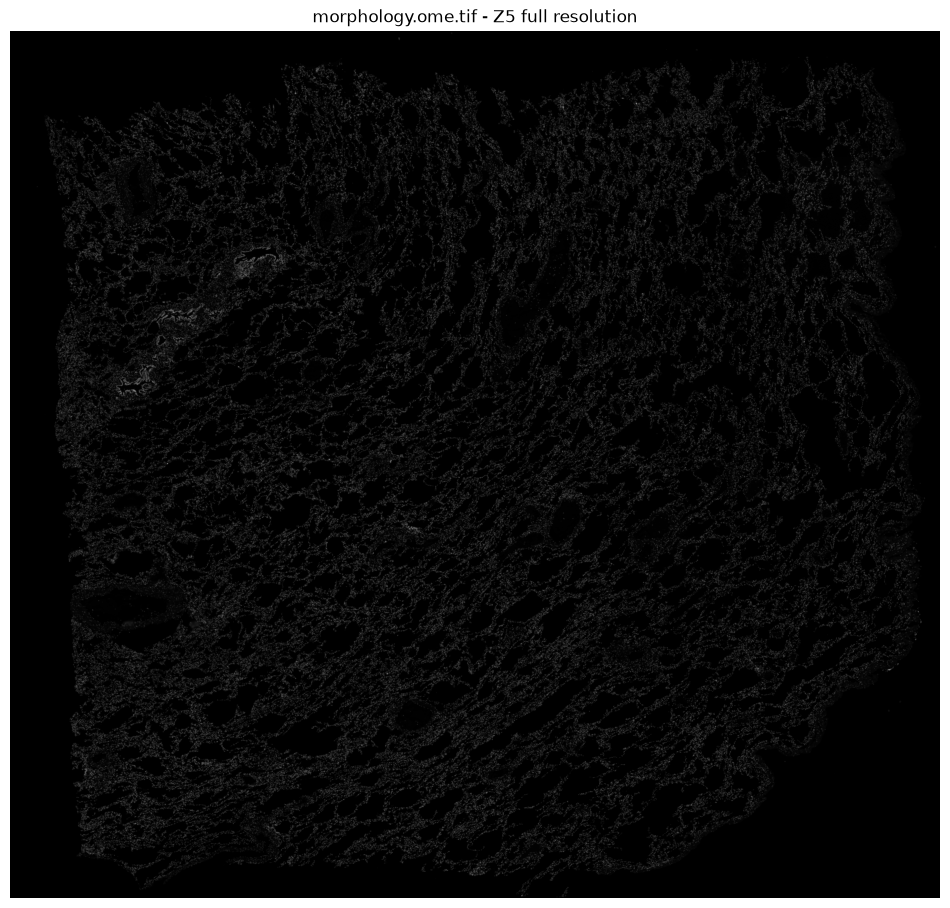

In [5]:
import tifffile
import zarr
import matplotlib.pyplot as plt

file_path = PATH_Xenium / "morphology.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    store = tif.series[0].aszarr()
    root = zarr.open(store, mode="r")

    first_key = list(root.keys())[0]
    arr = root[first_key]

    print("shape:", arr.shape)
    print("dtype:", arr.dtype)

    # 读取第 5 个 Z 层，完整分辨率
    img = arr[5, :, :]

plt.figure(figsize=(12, 12))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.title("morphology.ome.tif - Z5 full resolution")
plt.show()

# 数据拆解 morphology_focus.ome.tif

morphology_focus.ome.tif：是一张二维单层图像 \
shape = (47696, 51148)：表示图像高 47696、宽 51148 \
dtype = uint16：每个像素是 16 位整数强度值 \
axes = YX：只有二维空间，没有 Z 轴 \
page 数量 = 1：整个文件就是一张图 \
都读取70G

In [6]:
import tifffile

file_path = PATH_Xenium / "morphology_focus.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    print("series 数量:")
    print(len(tif.series))

    for i, series in enumerate(tif.series):
        print(
            i,
            "shape =", series.shape,
            "dtype =", series.dtype,
            "axes =", series.axes
        )
    print("\npage 数量:")
    print(len(tif.pages))

    print("\n第一个 series:")
    print("shape:", tif.series[0].shape)
    print("dtype:", tif.series[0].dtype)
    print("axes:", tif.series[0].axes)

series 数量:
1
0 shape = (47696, 51148) dtype = uint16 axes = YX

page 数量:
1

第一个 series:
shape: (47696, 51148)
dtype: uint16
axes: YX


所有层级：
4 shape = (2981, 3196) dtype = uint16
2 shape = (11924, 12787) dtype = uint16
7 shape = (372, 399) dtype = uint16
5 shape = (1490, 1598) dtype = uint16
0 shape = (47696, 51148) dtype = uint16
3 shape = (5962, 6393) dtype = uint16
1 shape = (23848, 25574) dtype = uint16
6 shape = (745, 799) dtype = uint16

原始图像：
shape: (47696, 51148)
dtype: uint16

局部区域：
shape: (1000, 1000)
min: 0
max: 5043
vmin: 7.0
vmax: 2887.0


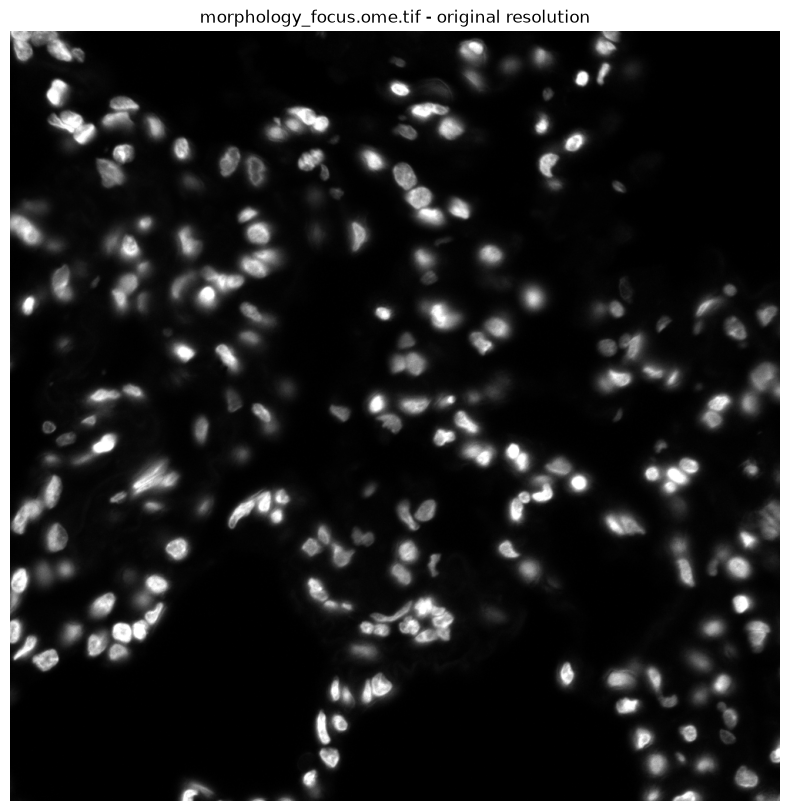

In [15]:
import tifffile
import zarr
import matplotlib.pyplot as plt
import numpy as np

file_path = PATH_Xenium / "morphology_focus.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    # 以 Zarr 方式打开 OME-TIFF
    store = tif.series[0].aszarr()
    root = zarr.open(store, mode="r")

    # 查看有哪些分辨率层级
    print("所有层级：")
    for key in root.keys():
        print(
            key,
            "shape =", root[key].shape,
            "dtype =", root[key].dtype
        )

    # 读取 0 层：原始分辨率
    arr = root["0"]

    print("\n原始图像：")
    print("shape:", arr.shape)
    print("dtype:", arr.dtype)

    # 截取 1000 × 1000 的原始分辨率区域
    img = arr[10000:11000, 10000:11000]

print("\n局部区域：")
print("shape:", img.shape)
print("min:", img.min())
print("max:", img.max())

# 拉伸灰度对比度，使结构更容易看清
vmin = np.percentile(img, 1)
vmax = np.percentile(img, 99.5)

print("vmin:", vmin)
print("vmax:", vmax)

# 显示
plt.figure(figsize=(10, 10))
plt.imshow(
    img,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
plt.axis("off")
plt.title("morphology_focus.ome.tif - original resolution")
plt.show()

# 数据拆解 morphology_mip.ome.tif

morphology_mip.ome.tif 是一张二维形态学图像 \
shape = (47696, 51148)：图像高度 47696，宽度 51148 \
dtype = uint16：每个像素用 16 位整数记录强度 \
axes = YX：只有二维空间，没有 Z 轴 \
series 数量 = 1：只有一个图像序列 \
page 数量 = 1：整个文件就是一张二维图 \
它和前面的几个文件可以这样理解： \
morphology.ome.tif：11 层 Z-stack，原始三维形态学图像 \
morphology_focus.ome.tif：二维 focus 图 \
morphology_mip.ome.tif：二维 MIP 图，也就是 Maximum Intensity Projection，最大强度投影 \
MIP 的意思是：对同一个 (x, y) 位置，把 11 个 Z 层里的像素值进行比较，取最大的那个

focus：强调“哪个 Z 层最清楚”，保留最佳聚焦信息 \
mip：不管清不清楚，11 层里谁最亮就取谁

In [16]:
import tifffile

file_path = PATH_Xenium / "morphology_mip.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    print("series 数量:")
    print(len(tif.series))

    for i, series in enumerate(tif.series):
        print(
            i,
            "shape =", series.shape,
            "dtype =", series.dtype,
            "axes =", series.axes
        )

    print("\npage 数量:")
    print(len(tif.pages))

    print("\n第一个 series:")
    print("shape:", tif.series[0].shape)
    print("dtype:", tif.series[0].dtype)
    print("axes:", tif.series[0].axes)

series 数量:
1
0 shape = (47696, 51148) dtype = uint16 axes = YX

page 数量:
1

第一个 series:
shape: (47696, 51148)
dtype: uint16
axes: YX


所有层级：
4 (2981, 3196) uint16
2 (11924, 12787) uint16
7 (372, 399) uint16
5 (1490, 1598) uint16
0 (47696, 51148) uint16
3 (5962, 6393) uint16
1 (23848, 25574) uint16
6 (745, 799) uint16

原图 shape: (47696, 51148)
dtype: uint16

局部图像 shape: (1000, 1000)
min: 14
max: 5459


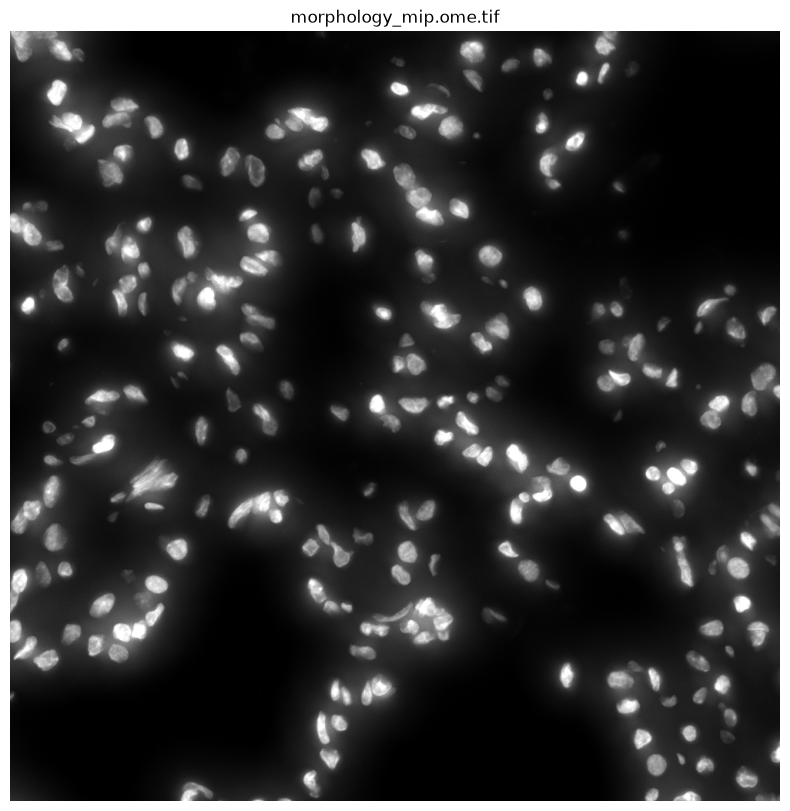

In [18]:
import tifffile
import zarr
import matplotlib.pyplot as plt
import numpy as np

file_path = PATH_Xenium / "morphology_mip.ome.tif"

with tifffile.TiffFile(file_path) as tif:
    store = tif.series[0].aszarr()
    root = zarr.open(store, mode="r")

    # 如果是多分辨率金字塔
    if isinstance(root, zarr.Group):
        print("所有层级：")
        for key in root.keys():
            print(key, root[key].shape, root[key].dtype)

        # 读取最高分辨率层
        arr = root["0"]
    else:
        arr = root

    print("\n原图 shape:", arr.shape)
    print("dtype:", arr.dtype)

    # 原始分辨率下截取 1000 × 1000 区域
    img = arr[10000:11000, 10000:11000]

print("\n局部图像 shape:", img.shape)
print("min:", img.min())
print("max:", img.max())

# 拉伸灰度范围
vmin = np.percentile(img, 1)
vmax = np.percentile(img, 99.5)

plt.figure(figsize=(10, 10))
plt.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
plt.axis("off")
plt.title("morphology_mip.ome.tif")
plt.show()

# 数据拆解 - gene_panel.json

gene_panel.json：记录 Xenium 实验中使用的基因 panel 配置，也就是这次实验设计上要检测哪些基因 \
metadata：文件元信息，包括校验值和界面属性 \
payload：主要实验配置内容 \
chemistry：Xenium 的解码体系和版本 \
customer：panel 使用方信息 \
designer：panel 的设计者、创建时间和版本 \
panel：基因 panel 的核心信息 \
species：Human \
tissue：Lung \
num_gene_targets：当前 add-on panel 含 100 个目标基因 \
base_panel_num_gene_targets：基础 panel 含 292 个基因 \
targets：每个目标基因的详细配置，包括基因名、Ensembl ID、codeword、gene coverage，以及属于 base panel 还是当前 add-on panel。

In [19]:
import json

file_path = PATH_Xenium / "gene_panel.json"

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("顶层类型:")
print(type(data))

print("\n顶层字段:")
if isinstance(data, dict):
    print(data.keys())

print("\n前面内容:")
print(data)

顶层类型:
<class 'dict'>

顶层字段:
dict_keys(['metadata', 'payload'])

前面内容:
{'metadata': {'sha256_checksum': '7af1c8c71004a0483f86b3a0d0916e21284fc20d667fb84230fe589e7bc3b73b', 'ui_props': {'visible': False}}, 'payload': {'chemistry': {'decoder': 'xenium_decoding_v1', 'version': 'v1'}, 'customer': {'email': None, 'name': '10x R&D'}, 'designer': {'date_created': '2022-01-01T00:00:00', 'designed_by': {'email': None, 'name': '10x R&D'}, 'version': 'Internal'}, 'panel': {'description': 'PD_346_LX16_hLung_100g_PD339-large-AddOn gene panel', 'identity': {'design_id': 'PD_346', 'name': 'hLung_100g'}, 'num_gene_targets': 100, 'species': 'Human', 'tissue': 'Lung', 'type': {'data': {'base_panel_identity': {'design_id': 'PD_339', 'name': 'hLung_292g'}, 'base_panel_num_gene_targets': 292}, 'descriptor': 'add_on'}}, 'spec_version': '0.1.0', 'targets': [{'codewords': [481], 'info': {'gene_coverage': 8}, 'source': {'category': 'current', 'identity': {'design_id': 'PD_346', 'name': 'hLung_100g'}}, 'type': {

# 数据拆解 - experiment.xenium

experiment.xenium：记录这次 Xenium 实验的整体配置信息、样本信息、成像参数和各类输出文件路径\
major_version / minor_version：experiment.xenium 文件格式版本，这里是 2.0\
run_name：本次实验运行名称，Human_Non_diseased_Lung_Add_on_FFPE\
run_start_time：实验开始时间，2023-05-02\
region_name：本次分析区域名称，Human_Non_diseased_Lung_With_Add_on_FFPE\
preservation_method：样本保存方式，这里是 FFPE\
num_cells：检测/分割得到的细胞数量，295883 个\
transcripts_per_cell：平均每个细胞约 71 个 transcript\
transcripts_per_100um：每 100 μm 对应的 transcript 密度指标，约 40.88\
panel_name：使用的 panel 名称，这里是 R&D Panel\
panel_organism：物种，Human\
panel_tissue_type：组织类型，Lung\
panel_num_targets_predesigned：预设计 panel 中有 292 个目标基因\
panel_num_targets_custom：额外自定义/add-on 的目标基因数为 100\
pixel_size：图像像素对应的实际空间尺寸，0.2125 μm/像素\
z_step_size：相邻 Z 层之间的间隔，3.0 μm\
instrument_sn / instrument_sw_version：仪器和仪器软件信息，这里被标记为 R&D\
analysis_sw_version：分析软件版本，xenium-1.3.0.5\
experiment_uuid / cassette_uuid / roi_uuid / well_uuid：实验内部标识符，这份数据里为空\
calibration_uuid：校准记录的内部 ID\
images：记录形态学图像文件的位置，包括 morphology.ome.tif、morphology_mip.ome.tif 和 morphology_focus.ome.tif\
xenium_explorer_files：记录 Xenium Explorer 使用的 Zarr 和分析文件位置，包括 transcripts、cells、cell features、analysis 和 summary。

In [20]:
import json

file_path = PATH_Xenium / "experiment.xenium"

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("顶层字段:")
print(data.keys())

for key, value in data.items():
    print("\n字段:", key)
    print("类型:", type(value))

    if isinstance(value, dict):
        print("子字段:", value.keys())
    elif isinstance(value, list):
        print("长度:", len(value))
        print("前3项:", value[:3])
    else:
        print("值:", value)

顶层字段:
dict_keys(['major_version', 'minor_version', 'run_name', 'run_start_time', 'region_name', 'preservation_method', 'num_cells', 'transcripts_per_cell', 'transcripts_per_100um', 'cassette_name', 'slide_id', 'panel_design_id', 'panel_name', 'panel_organism', 'panel_tissue_type', 'panel_num_targets_predesigned', 'panel_num_targets_custom', 'pixel_size', 'instrument_sn', 'instrument_sw_version', 'analysis_sw_version', 'experiment_uuid', 'cassette_uuid', 'roi_uuid', 'z_step_size', 'well_uuid', 'calibration_uuid', 'images', 'xenium_explorer_files'])

字段: major_version
类型: <class 'int'>
值: 2

字段: minor_version
类型: <class 'int'>
值: 0

字段: run_name
类型: <class 'str'>
值: Human_Non_diseased_Lung_Add_on_FFPE

字段: run_start_time
类型: <class 'str'>
值: 2023-05-02T22:32:52Z

字段: region_name
类型: <class 'str'>
值: Human_Non_diseased_Lung_With_Add_on_FFPE

字段: preservation_method
类型: <class 'str'>
值: FFPE

字段: num_cells
类型: <class 'int'>
值: 295883

字段: transcripts_per_cell
类型: <class 'int'>
值: 71

字段: t

# 数据拆解 - metrics_summary.csv

数据拆解 - metrics_summary.csv
metrics_summary.csv：记录这次 Xenium 实验的整体 QC 和汇总统计结果\
run_name：实验运行名称\
cassette_name：cassette 名称，这里为空\
region_name：分析区域名称\
panel_name：使用的基因 panel，这里是 R&D Panel\
region_area：整个分析区域面积，约 1.01 × 10^8\
total_cell_area：所有检测到的细胞区域总面积，约 5.87 × 10^7\
fraction_transcripts_decoded_q20：Q20 及以上、成功解码的 transcript 比例，约 84.13%\
fraction_predesigned_transcripts_decoded_q20：预设计 panel 中 Q20 及以上 transcript 的成功解码比例，约 83.15%\
fraction_custom_transcripts_decoded_q20：自定义/add-on panel 中 Q20 及以上 transcript 的成功解码比例，约 85.11%\
decoded_transcripts_per_100um2：每 100 μm² 区域内成功解码的 transcript 数量，约 40.88\
negative_control_probe_rate：阴性对照 probe 的信号比例，约 0.0748%，用于评估非特异性背景信号\
negative_control_codeword_rate：阴性对照 codeword 的信号比例，约 0.0367%，用于评估错误解码背景\
num_cells_detected：检测到的细胞数量，295883\
fraction_empty_cells：几乎没有检测到 transcript 的空细胞比例，约 0.0122%\
fraction_transcripts_assigned：成功分配到细胞的 transcript 比例，约 97.28%\
median_genes_per_cell：每个细胞检测到的基因数中位数，48\
median_predesigned_genes_per_cell：每个细胞中预设计 panel 基因数中位数，24\
median_custom_genes_per_cell：每个细胞中自定义/add-on 基因数中位数，24\
median_transcripts_per_cell：每个细胞 transcript 数量中位数，71\
median_predesigned_transcripts_per_cell：每个细胞中预设计 panel transcript 数量中位数，35\
median_custom_transcripts_per_cell：每个细胞中自定义/add-on panel transcript 数量中位数，36。

In [22]:
import pandas as pd

file_path = PATH_Xenium / "metrics_summary.csv"

df = pd.read_csv(file_path)

print("shape:")
print(df.shape)

print("\ncolumns:")
print(df.columns.tolist())

print("\n前5行:")
print(df.head())

print("\n数据类型:")
print(df.dtypes)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)

print(df)

shape:
(1, 21)

columns:
['run_name', 'cassette_name', 'region_name', 'panel_name', 'region_area', 'total_cell_area', 'fraction_transcripts_decoded_q20', 'fraction_predesigned_transcripts_decoded_q20', 'fraction_custom_transcripts_decoded_q20', 'decoded_transcripts_per_100um2', 'negative_control_probe_rate', 'negative_control_codeword_rate', 'num_cells_detected', 'fraction_empty_cells', 'fraction_transcripts_assigned', 'median_genes_per_cell', 'median_predesigned_genes_per_cell', 'median_custom_genes_per_cell', 'median_transcripts_per_cell', 'median_predesigned_transcripts_per_cell', 'median_custom_transcripts_per_cell']

前5行:
                              run_name  cassette_name  \
0  Human_Non_diseased_Lung_Add_on_FFPE            NaN   

                                region_name panel_name   region_area  \
0  Human_Non_diseased_Lung_With_Add_on_FFPE  R&D Panel  1.005548e+08   

   total_cell_area  fraction_transcripts_decoded_q20  \
0     5.870198e+07                          0.841

# 综合案例

选一个 cell

cells.parquet：找到这个细胞的 centroid / area / transcript_counts

transcripts.parquet：筛出属于这个 cell 的所有 transcript

看每个 transcript 的gene + x/y/z + qv + nucleus_distance

cell_boundaries.parquet：恢复这个 cell 的轮廓

nucleus_boundaries.parquet：恢复细胞核轮廓

cell_feature_matrix.h5：提取这个 cell 的完整 gene expression vector

morphology_focus.ome.tif: 裁这个细胞附近的 morphology 图像

gene_panel.json: 查询这些 gene 属于什么 panel / source

experiment.xenium: 补充实验整体信息

metrics_summary.csv: 补充全局 QC

Xenium path:
E:\Data\Xenium_Preview_Human_Non_diseased_Lung_With_Add_on_FFPE_outs
cells : True
transcripts : True
cell boundaries : True
nucleus boundaries : True
feature matrix : True
gene panel : True
experiment : True
metrics : True
morphology : True

cells shape:
(295883, 10)

cells columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

前5个细胞:
         cell_id   x_centroid  y_centroid  transcript_counts  \
0  b'aaaaaahk-1'   497.832559  855.178702                 15   
1  b'aaaacfah-1'  1666.102203  833.024384                 19   
2  b'aaaafpoc-1'  1738.557751  862.826160                 64   
3  b'aaaaimpp-1'  1702.586523  836.296915                 80   
4  b'aaaakahi-1'  1755.659229  865.216733                151   

   control_probe_counts  control_codeword_counts  unassigned_codeword_counts  \
0                     0                    

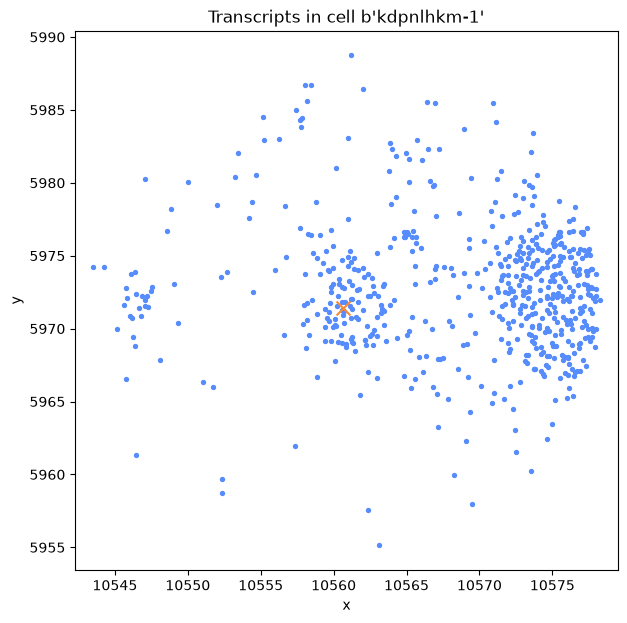


Cell boundary:
         cell_id      vertex_x     vertex_y
0  b'kdpnlhkm-1'  10560.400391  5954.037598
1  b'kdpnlhkm-1'  10549.987305  5957.437500
2  b'kdpnlhkm-1'  10545.525391  5962.325195
3  b'kdpnlhkm-1'  10543.187500  5970.399902
4  b'kdpnlhkm-1'  10546.587891  5981.662598

Nucleus boundary:
         cell_id      vertex_x     vertex_y
0  b'kdpnlhkm-1'  10560.400391  5968.912598
1  b'kdpnlhkm-1'  10558.912109  5969.337402
2  b'kdpnlhkm-1'  10558.062500  5970.399902
3  b'kdpnlhkm-1'  10558.062500  5972.100098
4  b'kdpnlhkm-1'  10558.487305  5972.737305


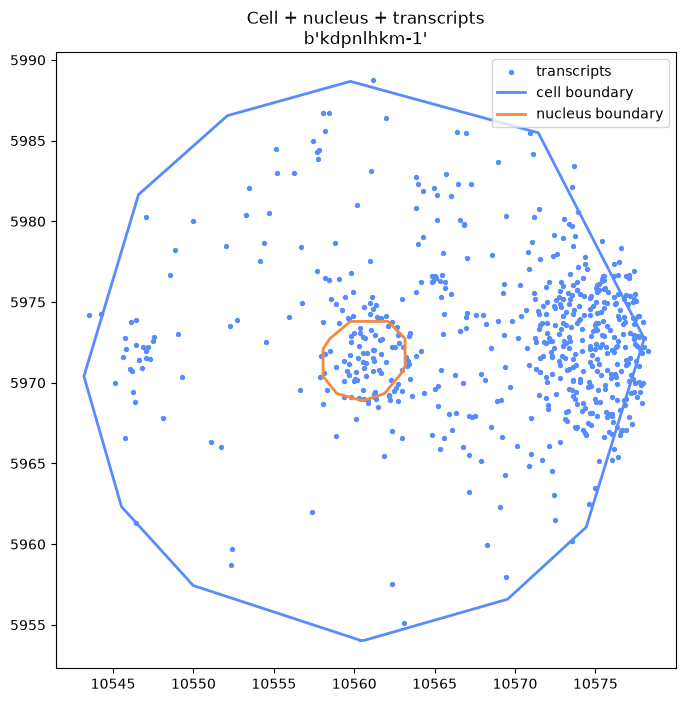

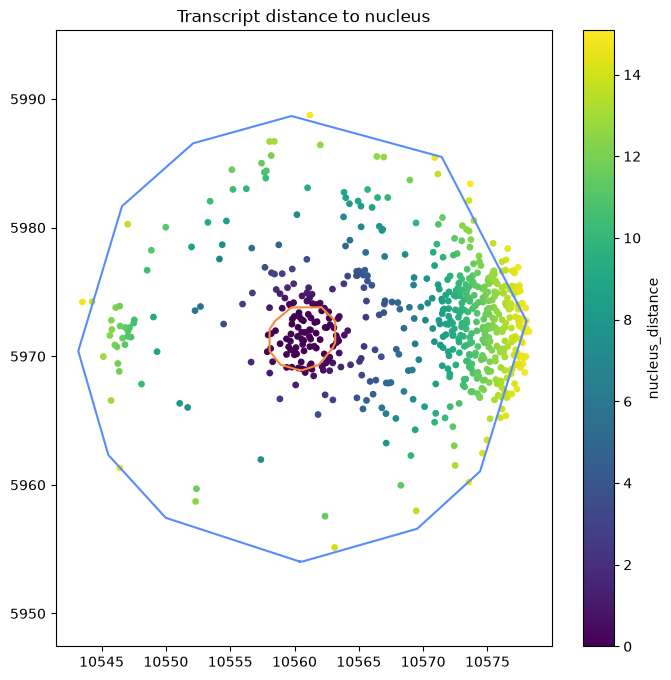

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import json
import tifffile

from scipy.sparse import csc_matrix

# =========================================================
# 0. 数据目录
# =========================================================

# 你之前已经定义过的话，这里不用重复
# PATH_Xenium = Path(r"E:\你的Xenium路径")

print("Xenium path:")
print(PATH_Xenium)

# =========================================================
# 1. 文件路径
# =========================================================

cells_path = PATH_Xenium / "cells.parquet"

transcripts_path = PATH_Xenium / "transcripts.parquet"

cell_boundaries_path = (
        PATH_Xenium / "cell_boundaries.parquet"
)

nucleus_boundaries_path = (
        PATH_Xenium / "nucleus_boundaries.parquet"
)

feature_matrix_path = (
        PATH_Xenium / "cell_feature_matrix.h5"
)

gene_panel_path = (
        PATH_Xenium / "gene_panel.json"
)

experiment_path = (
        PATH_Xenium / "experiment.xenium"
)

metrics_path = (
        PATH_Xenium / "metrics_summary.csv"
)

morphology_path = (
        PATH_Xenium / "morphology_focus.ome.tif"
)

# =========================================================
# 2. 检查文件
# =========================================================

paths = {
    "cells": cells_path,
    "transcripts": transcripts_path,
    "cell boundaries": cell_boundaries_path,
    "nucleus boundaries": nucleus_boundaries_path,
    "feature matrix": feature_matrix_path,
    "gene panel": gene_panel_path,
    "experiment": experiment_path,
    "metrics": metrics_path,
    "morphology": morphology_path,
}

for name, path in paths.items():
    print(
        name,
        ":",
        path.exists()
    )

# 3、读取细胞
cells = pd.read_parquet(
    cells_path
)

print("\ncells shape:")
print(cells.shape)

print("\ncells columns:")
print(cells.columns.tolist())

print("\n前5个细胞:")
print(cells.head())

# 选一个 transcript 比较多的 cell，这样后面画出来比较明显
# 过滤掉极端值
cells_valid = cells[
    cells["transcript_counts"] > 100
    ].copy()

# 取一个 transcript 较丰富的细胞
target_cell = (
    cells_valid
    .sort_values(
        "transcript_counts",
        ascending=False
    )
    .iloc[100]
)

cell_id = target_cell["cell_id"]

print("\n选择的 cell:")
print(target_cell)

print("\ncell_id:")
print(cell_id)

# 4 在 transcripts 中找这个 cell 的所有 transcript
import pyarrow.parquet as pq

transcript_table = pq.read_table(
    transcripts_path,
    filters=[
        (
            "cell_id",
            "=",
            cell_id
        )
    ]
)

cell_transcripts = (
    transcript_table
    .to_pandas()
)

print("\n该 cell transcript 数量:")
print(
    cell_transcripts.shape
)

print("\nTranscript columns:")
print(
    cell_transcripts.columns.tolist()
)

print("\n前10条 transcript:")
print(
    cell_transcripts.head(10)
)

# 5 看这个 cell 表达了哪些 gene
gene_counts = (
    cell_transcripts[
        "feature_name"
    ]
    .value_counts()
)

print("\n这个 cell 表达最多的 gene:")
print(
    gene_counts.head(20)
)

# 6、看 transcript 的空间分布
plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    cell_transcripts[
        "x_location"
    ],
    cell_transcripts[
        "y_location"
    ],
    s=8
)

plt.scatter(
    target_cell[
        "x_centroid"
    ],
    target_cell[
        "y_centroid"
    ],
    marker="x",
    s=100
)

plt.title(
    f"Transcripts in cell {cell_id}"
)

plt.xlabel(
    "x"
)

plt.ylabel(
    "y"
)

plt.axis(
    "equal"
)

plt.show()

# 7 Cell boundary
cell_boundary = (
    pd.read_parquet(
        cell_boundaries_path,
        filters=[
            (
                "cell_id",
                "=",
                cell_id
            )
        ]
    )
)

print("\nCell boundary:")
print(
    cell_boundary.head()
)

# 8 Nucleus boundary

nucleus_boundary = (
    pd.read_parquet(
        nucleus_boundaries_path,
        filters=[
            (
                "cell_id",
                "=",
                cell_id
            )
        ]
    )
)

print("\nNucleus boundary:")
print(
    nucleus_boundary.head()
)

# 绘图（三个信息）
plt.figure(
    figsize=(8, 8)
)

plt.scatter(
    cell_transcripts[
        "x_location"
    ],
    cell_transcripts[
        "y_location"
    ],
    s=8,
    label="transcripts"
)

plt.plot(
    cell_boundary[
        "vertex_x"
    ],
    cell_boundary[
        "vertex_y"
    ],
    linewidth=2,
    label="cell boundary"
)

if len(
        nucleus_boundary
) > 0:
    plt.plot(
        nucleus_boundary[
            "vertex_x"
        ],
        nucleus_boundary[
            "vertex_y"
        ],
        linewidth=2,
        label="nucleus boundary"
    )

plt.axis(
    "equal"
)

plt.legend()

plt.title(
    f"Cell + nucleus + transcripts\n{cell_id}"
)

plt.show()

# 9 看 nucleus_distance
plt.figure(
    figsize=(8, 8)
)

sc = plt.scatter(
    cell_transcripts[
        "x_location"
    ],
    cell_transcripts[
        "y_location"
    ],
    c=cell_transcripts[
        "nucleus_distance"
    ],
    s=15
)

plt.plot(
    cell_boundary[
        "vertex_x"
    ],
    cell_boundary[
        "vertex_y"
    ]
)

if len(
        nucleus_boundary
) > 0:
    plt.plot(
        nucleus_boundary[
            "vertex_x"
        ],
        nucleus_boundary[
            "vertex_y"
        ]
    )

plt.colorbar(
    sc,
    label="nucleus_distance"
)

plt.axis(
    "equal"
)

plt.title(
    "Transcript distance to nucleus"
)

plt.show()

[b'MARCO', b'SCD', b'FCGR3A', b'AIF1', b'CD68']


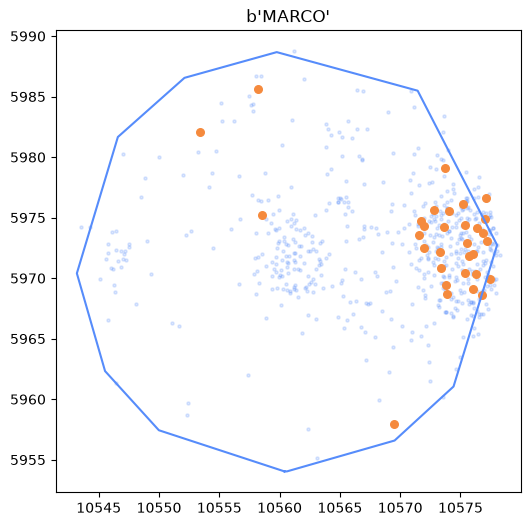

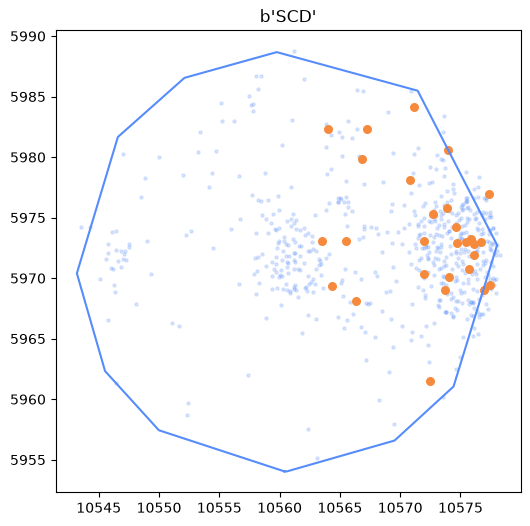

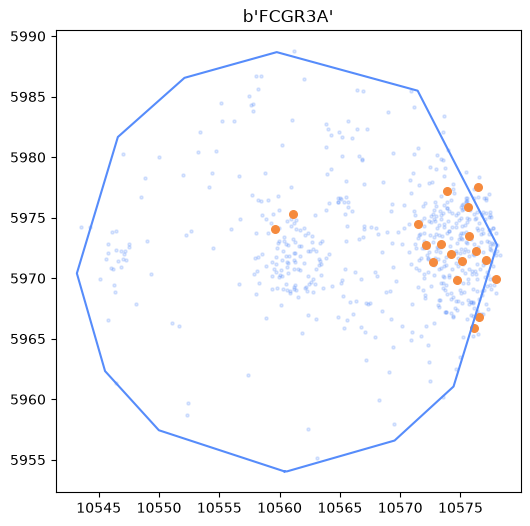

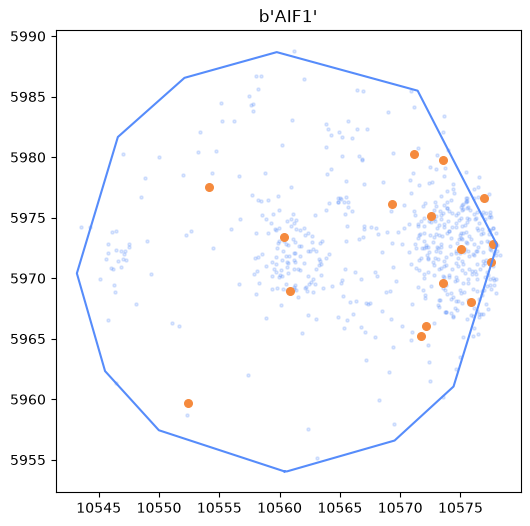

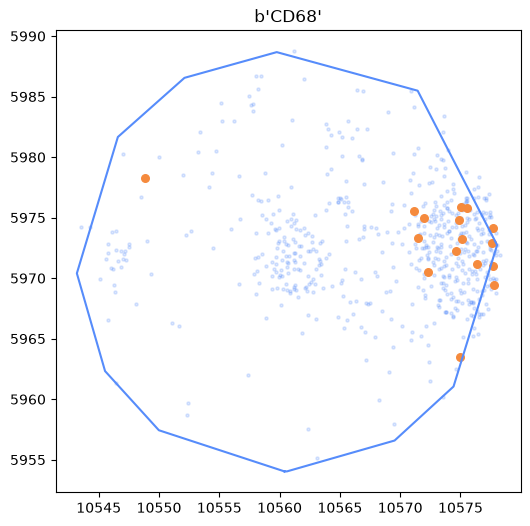

In [11]:
# 10 看不同 gene 的空间位置 - top5

top_genes = (
    gene_counts
    .head(5)
    .index
    .tolist()
)

print(
    top_genes
)
for gene in top_genes:
    gene_df = (
        cell_transcripts[
            cell_transcripts[
                "feature_name"
            ] == gene
            ]
    )

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        cell_transcripts[
            "x_location"
        ],
        cell_transcripts[
            "y_location"
        ],
        s=5,
        alpha=0.2
    )

    plt.scatter(
        gene_df[
            "x_location"
        ],
        gene_df[
            "y_location"
        ],
        s=30
    )

    plt.plot(
        cell_boundary[
            "vertex_x"
        ],
        cell_boundary[
            "vertex_y"
        ]
    )

    plt.axis(
        "equal"
    )

    plt.title(
        gene
    )

    plt.show()

(47696, 51148)
cell micron: 10560.667285156249 5971.40107421875
cell pixel: 49697 28100


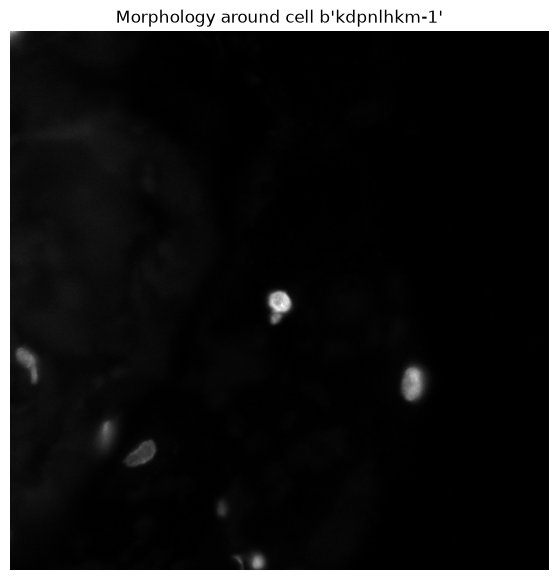

In [19]:
# morphology_focus.ome.tif 裁一个细胞附近
with tifffile.TiffFile(
        morphology_path
) as tif:
    print(
        tif.series[0].shape
    )

    store = tif.series[0].aszarr()

pixel_size = 0.2125

cell_x_um = float(
    target_cell[
        "x_centroid"
    ]
)

cell_y_um = float(
    target_cell[
        "y_centroid"
    ]
)

cell_x_px = int(
    cell_x_um
    / pixel_size
)

cell_y_px = int(
    cell_y_um
    / pixel_size
)

print(
    "cell micron:",
    cell_x_um,
    cell_y_um
)

print(
    "cell pixel:",
    cell_x_px,
    cell_y_px
)

import zarr

with tifffile.TiffFile(
        morphology_path
) as tif:
    root = zarr.open(
        tif.series[0].aszarr(),
        mode="r"
    )

    fullres = root["0"]

    crop_size = 300

    x0 = max(
        0,
        cell_x_px - crop_size
    )

    x1 = min(
        fullres.shape[1],
        cell_x_px + crop_size
    )

    y0 = max(
        0,
        cell_y_px - crop_size
    )

    y1 = min(
        fullres.shape[0],
        cell_y_px + crop_size
    )

    crop = fullres[
        y0:y1,
        x0:x1
    ]

    plt.figure(
        figsize=(7, 7)
    )

plt.imshow(
    crop,
    cmap="gray"
)

plt.title(
    f"Morphology around cell {cell_id}"
)

plt.axis(
    "off"
)

plt.show()